# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Rini Wulandari
- **Email:** riniwulandari1205@gmail.com
- **ID Dicoding:** rini_wulandariz580

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Pertanyaan disusun dengan metode **SMART** (Specific, Measurable, Action-Oriented, Relevant, Time-bound). Periode analisis adalah **Januari 2017 - Agustus 2018** (bulan penuh; data 2016 dan September-Oktober 2018 sangat sedikit sehingga tidak representatif).

- **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan total revenue tertinggi (Top 10) pada periode Januari 2017 - Agustus 2018, dan berapa persen pertumbuhan revenue tiap kategori tersebut pada Januari-Agustus 2018 dibandingkan Januari-Agustus 2017?
- **Pertanyaan 2:** Berapa rata-rata waktu pengiriman (hari) dan rata-rata skor review di tiap state pelanggan pada periode Januari 2017 - Agustus 2018, serta seberapa besar selisih skor review antara pesanan yang terlambat dan yang tepat waktu?
- **Pertanyaan 3:** Bagaimana segmentasi pelanggan berdasarkan RFM (Recency, Frequency, Monetary) pada periode Januari 2017 - Agustus 2018, dan segmen mana yang menyumbang revenue terbesar?

## Import Semua Packages/Library yang Digunakan

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from matplotlib.ticker import FuncFormatter

sns.set_theme(style='whitegrid')
ACCENT, GRAY, ALERT = '#2A6F97', '#BFC5CC', '#C0392B'

## Data Wrangling

### Gathering Data

#### Load seluruh dataset

In [4]:
orders = pd.read_csv('orders_dataset.csv')
items = pd.read_csv('order_items_dataset.csv')
products = pd.read_csv('products_dataset.csv')
translation = pd.read_csv('product_category_name_translation.csv')
customers = pd.read_csv('customers_dataset.csv')
reviews = pd.read_csv('order_reviews_dataset.csv')
payments = pd.read_csv('order_payments_dataset.csv')
sellers = pd.read_csv('sellers_dataset.csv')
geo = pd.read_csv('geolocation_dataset.csv')

for name, d in {'orders': orders, 'items': items, 'products': products, 'translation': translation,
                'customers': customers, 'reviews': reviews, 'payments': payments,
                'sellers': sellers, 'geolocation': geo}.items():
    print(f'{name:12s} -> {d.shape[0]:>8,} baris, {d.shape[1]} kolom')
orders.head()

orders       ->   99,441 baris, 8 kolom
items        ->  112,650 baris, 7 kolom
products     ->   32,951 baris, 9 kolom
translation  ->       71 baris, 2 kolom
customers    ->   99,441 baris, 5 kolom
reviews      ->   99,224 baris, 7 kolom
payments     ->  103,886 baris, 5 kolom
sellers      ->    3,095 baris, 4 kolom
geolocation  -> 1,000,163 baris, 5 kolom


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Terdapat 9 tabel yang saling berelasi: orders menjadi pusat dan terhubung ke items (via order_id), customers (via customer_id), reviews, dan payments. items terhubung ke products dan sellers.
- geolocation memiliki lebih dari 1 juta baris, jauh lebih besar dibanding tabel lain, sehingga kemungkinan banyak duplikasi.
- Tabel customers memiliki customer_id (unik per pesanan) dan customer_unique_id (unik per orang). Untuk analisis RFM, customer_unique_id yang harus dipakai.

### Assessing Data

#### Identifying masalah pada tabel **orders**

In [5]:
for c in ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
          'order_delivered_customer_date', 'order_estimated_delivery_date']:
    orders[c] = pd.to_datetime(orders[c])

print('Missing value:'); print(orders.isna().sum()); print()
print('Status order:'); print(orders.order_status.value_counts()); print()
print('Rentang tanggal pembelian:', orders.order_purchase_timestamp.min(), 's/d', orders.order_purchase_timestamp.max())
print('Status delivered tapi tanggal diterima kosong:',
      ((orders.order_status == 'delivered') & orders.order_delivered_customer_date.isna()).sum())
print('Status bukan delivered tapi tanggal diterima terisi:',
      ((orders.order_status != 'delivered') & orders.order_delivered_customer_date.notna()).sum())
print('Barang diterima pelanggan lebih awal dari diserahkan ke kurir:',
      (orders.order_delivered_carrier_date > orders.order_delivered_customer_date).sum())
print('Duplikat order_id:', orders.order_id.duplicated().sum())
print()
print(orders.order_purchase_timestamp.dt.to_period('M').value_counts().sort_index().to_string())

Missing value:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Status order:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Rentang tanggal pembelian: 2016-09-04 21:15:19 s/d 2018-10-17 17:30:18
Status delivered tapi tanggal diterima kosong: 8
Status bukan delivered tapi tanggal diterima terisi: 6
Barang diterima pelanggan lebih awal dari diserahkan ke kurir: 23
Duplikat order_id: 0

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    40

#### Identifying masalah pada tabel **products** dan **product_category_name_translation**

In [6]:
print(products.isna().sum()); print()
missing_translation = set(products.product_category_name.dropna()) - set(translation.product_category_name)
print('Kategori tanpa terjemahan:', missing_translation)
print('Duplikat product_id:', products.product_id.duplicated().sum())

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Kategori tanpa terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}
Duplikat product_id: 0


#### Identifying masalah pada tabel **reviews**, **order_items**, dan **payments**

In [7]:
print('Duplikat review_id    :', reviews.review_id.duplicated().sum())
print('Order dengan >1 review:', reviews.order_id.duplicated().sum())
print('Rentang skor review   :', reviews.review_score.min(), '-', reviews.review_score.max())
print()
print(items[['price', 'freight_value']].describe().round(2)); print()
q1, q3 = items.price.quantile([.25, .75]); iqr = q3 - q1
n_out = (items.price > q3 + 1.5 * iqr).sum()
print(f'Outlier harga (IQR): {n_out:,} item ({n_out / len(items):.1%}); harga maksimum {items.price.max():,.0f}')
print('Pembayaran bernilai 0:', (payments.payment_value == 0).sum(), '| tipe not_defined:', (payments.payment_type == 'not_defined').sum())

Duplikat review_id    : 814
Order dengan >1 review: 551
Rentang skor review   : 1 - 5

           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max      6735.00         409.68

Outlier harga (IQR): 8,427 item (7.5%); harga maksimum 6,735
Pembayaran bernilai 0: 9 | tipe not_defined: 3


#### Identifying masalah pada tabel **geolocation**

In [8]:
print('Baris duplikat penuh:', geo.duplicated().sum(), f'({geo.duplicated().mean():.1%})')
out_brazil = geo[(geo.geolocation_lat > 5.3) | (geo.geolocation_lat < -33.8) |
                 (geo.geolocation_lng < -73.9) | (geo.geolocation_lng > -34.8)]
print('Koordinat di luar wilayah Brasil:', len(out_brazil))
print('Jumlah zip prefix unik:', geo.geolocation_zip_code_prefix.nunique())
print('Contoh penulisan kota tidak konsisten:',
      geo[geo.geolocation_city.str.contains('sao paulo|são paulo|sãopaulo|sa£o', regex=True)].geolocation_city.unique())

Baris duplikat penuh: 261831 (26.2%)
Koordinat di luar wilayah Brasil: 47
Jumlah zip prefix unik: 19015
Contoh penulisan kota tidak konsisten: ['sao paulo' 'são paulo' 'sãopaulo' 'sa£o paulo' 'morro de sao paulo'
 'morro de são paulo' 'são paulo do potengi' 'sao paulo do potengi'
 'são paulo de olivença' 'sao paulo de olivenca' 'sao paulo das missoes'
 'são paulo das missões']


**Steps to Take:**

| No | Tabel | Masalah | Jenis | Tindakan pada tahap Cleaning |
|---|---|---|---|---|
| 1 | orders | 2.965 `order_delivered_customer_date` kosong; 8 di antaranya berstatus *delivered* | Missing value | Analisis pengiriman hanya memakai pesanan *delivered* yang tanggal diterimanya terisi |
| 2 | orders | Status tidak seragam (canceled, unavailable, shipped, dst.) dan 23 pesanan diterima lebih awal dari diserahkan ke kurir | Inconsistent / inaccurate value | Hanya pesanan *delivered* yang dipakai untuk revenue dan pengiriman; baris tanggal tidak logis dikeluarkan |
| 3 | orders | Data 2016 dan Sep-Okt 2018 sangat sedikit (< 20 pesanan/bulan pada 2018-09/10) | Outlier periode | Batasi periode analisis ke Jan 2017 - Agu 2018 |
| 4 | products | 610 produk tanpa kategori; 2 kategori tanpa terjemahan Inggris | Missing value & inconsistent value | Isi `unknown`, tambahkan terjemahan manual |
| 5 | reviews | 551 `order_id` memiliki lebih dari 1 review | Duplicate data | Ambil review dengan `review_answer_timestamp` terbaru per pesanan |
| 6 | geolocation | 261.831 baris duplikat penuh, 47 koordinat di luar Brasil, penulisan kota tidak konsisten (`sao paulo`, `são paulo`, `sãopaulo`) | Duplicate, invalid & inconsistent value | Hapus duplikat, buang koordinat di luar Brasil, agregasi per zip prefix (rata-rata lat/lng) |
| 7 | order_items | Harga ekstrem (maks. 6.735) | Outlier | Dipertahankan karena transaksi valid (barang mahal), tidak mengubah kesimpulan karena analisis memakai total dan rata-rata per kategori |

**Insight:** (Opsional)
- Masalah terbanyak ada pada **geolocation** (duplikat dan koordinat tidak valid), sedangkan **orders** memerlukan penyaringan status dan periode.
- Kolom tanggal pada **orders** berformat teks sehingga harus dikonversi ke datetime sebelum dihitung lama pengirimannya.

### Cleaning Data

#### Fixing masalah pada tabel **orders**

pilih pesanan *delivered*, tanggal terisi, tanggal logis, dan periode Jan 2017 - Agu 2018.

In [9]:
orders_clean = orders[(orders.order_status == 'delivered') & orders.order_delivered_customer_date.notna()].copy()
orders_clean = orders_clean[~(orders_clean.order_delivered_carrier_date > orders_clean.order_delivered_customer_date)]
orders_clean = orders_clean[(orders_clean.order_purchase_timestamp >= '2017-01-01') &
                            (orders_clean.order_purchase_timestamp < '2018-09-01')]
print('Pesanan sebelum:', len(orders), '| sesudah cleaning:', len(orders_clean))

Pesanan sebelum: 99441 | sesudah cleaning: 96184


#### Fixing masalah pada tabel **products**

isi kategori kosong dan lengkapi terjemahan.

In [10]:
extra = pd.DataFrame({'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'],
                      'product_category_name_english': ['pc_gamer', 'portable_kitchen_food_preparers']})
translation_full = pd.concat([translation, extra], ignore_index=True)
products_clean = products.merge(translation_full, on='product_category_name', how='left')
products_clean['product_category'] = products_clean.product_category_name_english.fillna('unknown')
print(products_clean.product_category.eq('unknown').sum(), 'produk berkategori unknown')

610 produk berkategori unknown


#### Fixing masalah pada tabel **reviews**

satu review (terbaru) per pesanan.

In [11]:
reviews['review_answer_timestamp'] = pd.to_datetime(reviews.review_answer_timestamp)
reviews_clean = (reviews.sort_values('review_answer_timestamp')
                        .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
print('Duplikat order_id setelah cleaning:', reviews_clean.order_id.duplicated().sum())

Duplikat order_id setelah cleaning: 0


#### Fixing masalah pada tabel **geolocation**

hapus duplikat, koordinat tidak valid, lalu agregasi per zip prefix.

In [12]:
geo_clean = geo.drop_duplicates()
geo_clean = geo_clean[(geo_clean.geolocation_lat.between(-33.8, 5.3)) & (geo_clean.geolocation_lng.between(-73.9, -34.8))]
geo_zip = (geo_clean.groupby('geolocation_zip_code_prefix')
                    .agg(lat=('geolocation_lat', 'mean'), lng=('geolocation_lng', 'mean')).reset_index())
print('Baris geolocation:', len(geo), '->', len(geo_clean), '| zip prefix unik:', len(geo_zip))

Baris geolocation: 1000163 -> 738294 | zip prefix unik: 19010


#### Penggabungan semua tabel menjadi **main_data**

(satu baris = satu item pesanan).

In [13]:
main_df = (orders_clean
           .merge(items, on='order_id')
           .merge(products_clean[['product_id', 'product_category']], on='product_id', how='left')
           .merge(customers, on='customer_id')
           .merge(reviews_clean, on='order_id', how='left'))
main_df['delivery_days'] = ((main_df.order_delivered_customer_date - main_df.order_purchase_timestamp)
                            .dt.total_seconds() / 86400).round(2)
main_df['is_late'] = main_df.order_delivered_customer_date > main_df.order_estimated_delivery_date
main_df['product_category'] = main_df.product_category.fillna('unknown')

print('Baris main_data:', len(main_df), '| pesanan unik:', main_df.order_id.nunique(),
      '| pelanggan unik:', main_df.customer_unique_id.nunique())
print('Review kosong:', main_df.review_score.isna().sum())
print('Missing value tersisa pada kolom kunci:'); print(main_df[['price', 'delivery_days', 'customer_state', 'product_category']].isna().sum())

Baris main_data: 109827 | pesanan unik: 96184 | pelanggan unik: 93080
Review kosong: 823
Missing value tersisa pada kolom kunci:
price               0
delivery_days       0
customer_state      0
product_category    0
dtype: int64


In [14]:
# Menyimpan data untuk dashboard
cols = ['order_id', 'customer_unique_id', 'order_purchase_timestamp', 'order_delivered_customer_date',
        'order_estimated_delivery_date', 'product_category', 'price', 'freight_value',
        'customer_state', 'review_score', 'delivery_days', 'is_late']
main_df[cols].to_csv('main_data.csv', index=False)

# Koordinat pusat tiap state (rata-rata koordinat zip pelanggan)
cust_geo = customers.merge(geo_zip, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='inner')
state_geo = cust_geo.groupby('customer_state').agg(lat=('lat', 'mean'), lng=('lng', 'mean')).round(4).reset_index()
state_geo.to_csv('state_geo.csv', index=False)
print(state_geo.shape)

(27, 3)


**Insight:**
- Data siap analisis: pesanan *delivered* periode Jan 2017 - Agu 2018 dengan satu review per pesanan dan kategori yang sudah berbahasa Inggris.
- Hanya sebagian kecil review yang kosong (pesanan tanpa review), sehingga rata-rata skor tetap representatif.
- Dataset gabungan disimpan sebagai **main_data.csv**, dan koordinat tiap state disimpan sebagai **state_geo.csv** untuk dashboard.

## Exploratory Data Analysis (EDA)

### Explore Data Umum

In [15]:
order_level = main_df.drop_duplicates('order_id')
print('Total revenue (harga barang) :', f"{main_df.price.sum():,.0f}")
print('Total pesanan                :', f"{order_level.order_id.nunique():,}")
print('Rata-rata skor review        :', round(order_level.review_score.mean(), 2))
print('Rata-rata waktu pengiriman   :', round(order_level.delivery_days.mean(), 1), 'hari')
print('Persentase pesanan terlambat :', f"{order_level.is_late.mean():.1%}")
main_df[['price', 'freight_value', 'delivery_days', 'review_score']].describe().round(2)

Total revenue (harga barang) : 13,176,606
Total pesanan                : 96,184
Rata-rata skor review        : 4.16
Rata-rata waktu pengiriman   : 12.5 hari
Persentase pesanan terlambat : 8.1%


,price,freight_value,delivery_days,review_score
count,109827.00,109827.00,109827.00,109004.00
mean,119.98,19.95,12.45,4.08
std,182.38,15.70,9.43,1.35
min,0.85,0.00,0.53,1.00
25%,39.90,13.08,6.73,4.00
50%,74.90,16.26,10.18,5.00
75%,134.17,21.15,15.50,5.00
max,6735.00,409.68,209.63,5.00


### Explore Pertanyaan 1: Kategori dengan revenue tertinggi dan pertumbuhannya

In [16]:
rev_cat = main_df.groupby('product_category').price.sum().sort_values(ascending=False)
top10 = rev_cat.head(10)
print(top10.round(0)); print()
print(f'Kontribusi Top 10 terhadap total revenue: {top10.sum() / rev_cat.sum():.1%}')

main_df['year'] = main_df.order_purchase_timestamp.dt.year
main_df['month'] = main_df.order_purchase_timestamp.dt.month
ytd = (main_df[main_df.month <= 8].pivot_table(index='product_category', columns='year', values='price', aggfunc='sum'))
ytd['growth_pct'] = (ytd[2018] / ytd[2017] - 1) * 100
growth_top10 = ytd.loc[top10.index].round(1)
growth_top10

product_category
health_beauty            1229426.0
watches_gifts            1163121.0
bed_bath_table           1022541.0
sports_leisure            952476.0
computers_accessories     887762.0
furniture_decor           705756.0
housewares                614143.0
cool_stuff                609070.0
auto                      577695.0
garden_tools              468853.0
Name: price, dtype: float64

Kontribusi Top 10 terhadap total revenue: 62.5%


year,2017,2018,growth_pct
product_category,,,
health_beauty,243389.9,755724.5,210.5
watches_gifts,201071.0,687577.2,242.0
bed_bath_table,254030.2,532358.8,109.6
sports_leisure,216360.3,517166.3,139.0
computers_accessories,214448.4,496158.3,131.4
furniture_decor,170377.6,381649.6,124.0
housewares,127336.0,391823.5,207.7
cool_stuff,206218.4,227743.7,10.4
auto,125221.5,343288.3,174.1


In [17]:
main_df['order_month'] = main_df.order_purchase_timestamp.dt.to_period('M').dt.to_timestamp()
monthly = main_df.groupby('order_month').price.sum()
print(monthly.round(0).to_string())

order_month
2017-01-01    111610.0
2017-02-01    233833.0
2017-03-01    359110.0
2017-04-01    340670.0
2017-05-01    488869.0
2017-06-01    421781.0
2017-07-01    480005.0
2017-08-01    554228.0
2017-09-01    607400.0
2017-10-01    648248.0
2017-11-01    987648.0
2017-12-01    726033.0
2018-01-01    924645.0
2018-02-01    826437.0
2018-03-01    953356.0
2018-04-01    973534.0
2018-05-01    977545.0
2018-06-01    855592.0
2018-07-01    867486.0
2018-08-01    838577.0


### Explore Pertanyaan 2: Waktu pengiriman dan skor review per state

In [18]:
state_stats = (order_level.groupby('customer_state')
               .agg(orders=('order_id', 'count'), avg_delivery_days=('delivery_days', 'mean'),
                    avg_review=('review_score', 'mean'), late_rate=('is_late', 'mean'))
               .sort_values('avg_delivery_days'))
state_stats['late_rate'] *= 100
print(state_stats.round(2).head(5)); print('...'); print(state_stats.round(2).tail(5))
print()
print('Korelasi waktu pengiriman vs skor review antar state:',
      round(state_stats.avg_delivery_days.corr(state_stats.avg_review), 2))
late_review = order_level.groupby('is_late').review_score.agg(['mean', 'count']).round(2)
print(); print(late_review)

                orders  avg_delivery_days  avg_review  late_rate
customer_state                                                  
SP               40387               8.74        4.25       5.90
PR                4903              11.97        4.24       5.02
MG               11315              11.99        4.19       5.63
DF                2074              12.94        4.13       7.09
SC                3535              14.95        4.13       9.79
...
                orders  avg_delivery_days  avg_review  late_rate
customer_state                                                  
PA                 942              23.76        3.91      12.42
AL                 396              24.52        3.85      23.99
AM                 145              26.43        4.24       4.14
AP                  67              27.19        4.24       4.48
RR                  40              29.91        3.90      12.50

Korelasi waktu pengiriman vs skor review antar state: -0.46

         mean  count
is_

In [19]:
# Binning: kelompokkan lama pengiriman
bins = [0, 7, 14, 21, 30, np.inf]
labels = ['<= 7 hari', '8-14 hari', '15-21 hari', '22-30 hari', '> 30 hari']
order_level = order_level.copy()
order_level['delivery_bin'] = pd.cut(order_level.delivery_days, bins=bins, labels=labels)
bin_stats = order_level.groupby('delivery_bin', observed=True).review_score.agg(['mean', 'count']).round(2)
bin_stats

,mean,count
delivery_bin,,
<= 7 hari,4.42,25962
8-14 hari,4.31,39871
15-21 hari,4.14,17506
22-30 hari,3.61,7820
> 30 hari,2.24,4382


**Insight:** (Opsional)
- **Pertanyaan 1:** Top 10 kategori menyumbang sekitar 62% revenue. Kategori terbesar adalah **health_beauty**, disusul **watches_gifts** dan **bed_bath_table**. Seluruh Top 10 tumbuh pada Jan-Agu 2018 dibanding periode yang sama 2017, dengan pertumbuhan tertinggi pada **watches_gifts** dan **health_beauty**, dan terendah pada **cool_stuff**.
- **Pertanyaan 2:** Rata-rata pengiriman sekitar 12,5 hari dan sekitar 8% pesanan terlambat. State dengan pengiriman tercepat adalah SP, sedangkan state di utara/timur laut (misalnya RR, AP, AM, PA, AL) paling lama. Pesanan terlambat memiliki skor review jauh lebih rendah dibanding pesanan tepat waktu.

## Visualization & Explanatory Analysis

Prinsip desain yang diterapkan: judul berupa kesimpulan (bukan sekadar label), warna aksen hanya untuk hal yang ingin ditonjolkan (sisanya abu-abu), sumbu berlabel dan berformat ringkas, bar diurutkan, tanpa elemen dekoratif (tanpa 3D/pie), dan sumbu bar selalu dimulai dari nol demi integritas visual.

### Pertanyaan 1: Top 10 kategori produk berdasarkan revenue dan pertumbuhannya

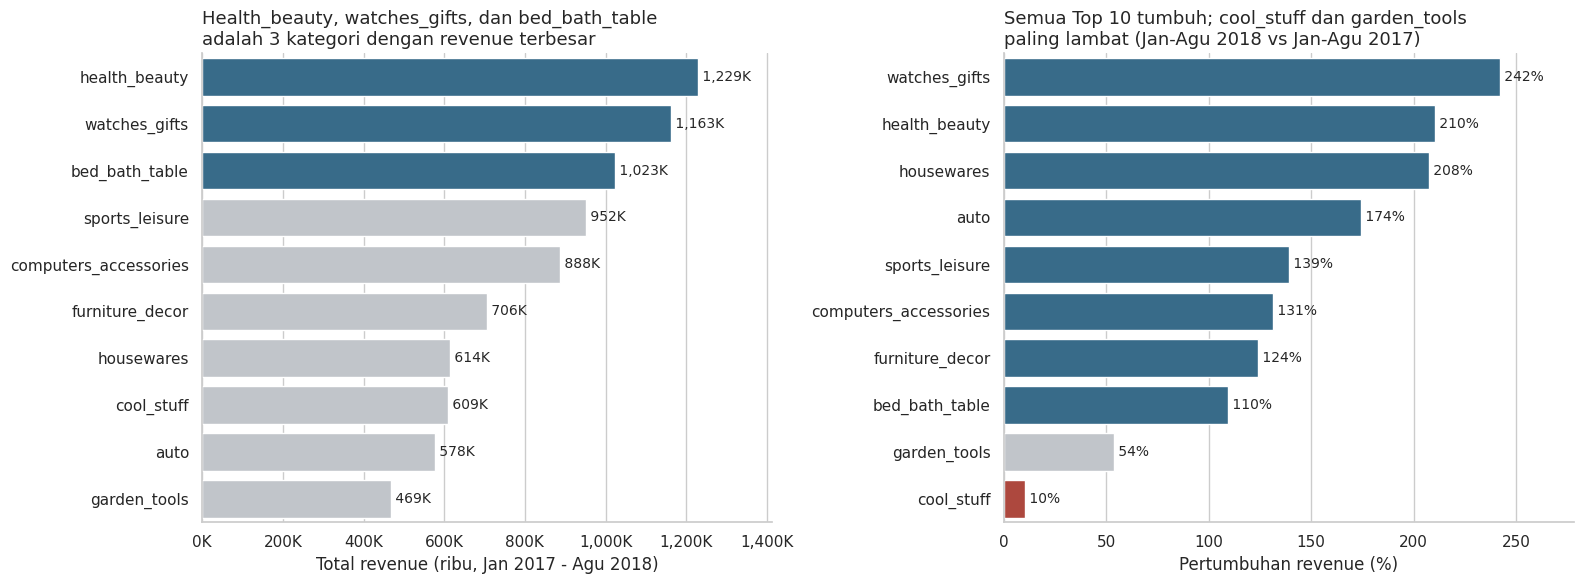

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel kiri: revenue
ax = axes[0]
colors = [ACCENT] * 3 + [GRAY] * 7
sns.barplot(x=top10.values, y=top10.index, palette=colors, hue=top10.index, legend=False, ax=ax)
ax.set_title('Health_beauty, watches_gifts, dan bed_bath_table\nadalah 3 kategori dengan revenue terbesar', loc='left', fontsize=13)
ax.set_xlabel('Total revenue (ribu, Jan 2017 - Agu 2018)'); ax.set_ylabel('')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1000:,.0f}K'))
for i, v in enumerate(top10.values):
    ax.text(v, i, f' {v / 1000:,.0f}K', va='center', fontsize=10)
ax.set_xlim(0, top10.max() * 1.15)

# Panel kanan: pertumbuhan YoY
ax = axes[1]
g = growth_top10.growth_pct.sort_values(ascending=False)
colors = [ACCENT if v > 100 else GRAY for v in g.values]
colors = [ALERT if v < 50 else c for v, c in zip(g.values, colors)]
sns.barplot(x=g.values, y=g.index, palette=colors, hue=g.index, legend=False, ax=ax)
ax.set_title('Semua Top 10 tumbuh; cool_stuff dan garden_tools\npaling lambat (Jan-Agu 2018 vs Jan-Agu 2017)', loc='left', fontsize=13)
ax.set_xlabel('Pertumbuhan revenue (%)'); ax.set_ylabel('')
for i, v in enumerate(g.values):
    ax.text(v, i, f' {v:,.0f}%', va='center', fontsize=10)
ax.set_xlim(0, g.max() * 1.15)
sns.despine()
plt.tight_layout(); plt.show()

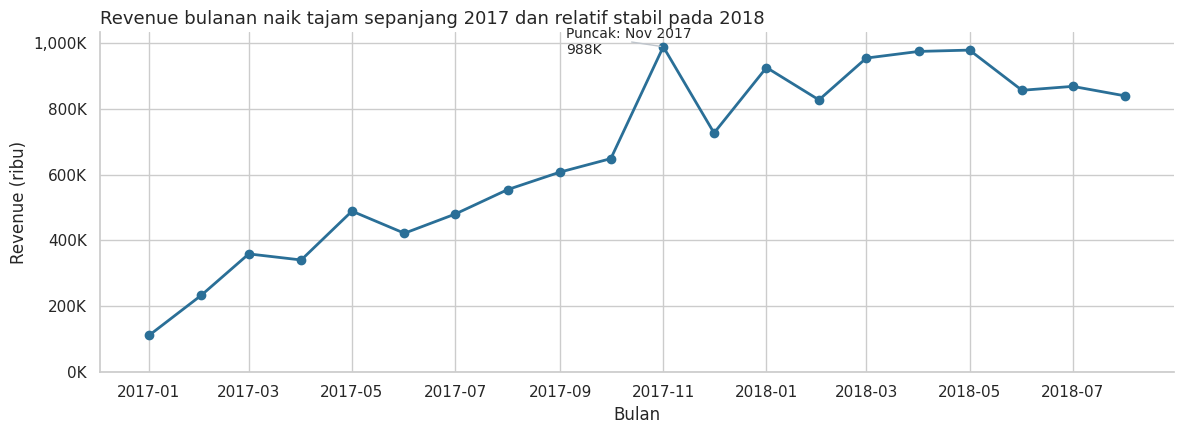

In [21]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly.values, color=ACCENT, marker='o', linewidth=2)
peak = monthly.idxmax()
ax.annotate(f'Puncak: {peak:%b %Y}\n{monthly.max() / 1000:,.0f}K', (peak, monthly.max()), textcoords='offset points',
            xytext=(-70, -5), fontsize=10, arrowprops=dict(arrowstyle='-', color=GRAY))
ax.set_title('Revenue bulanan naik tajam sepanjang 2017 dan relatif stabil pada 2018', loc='left', fontsize=13)
ax.set_xlabel('Bulan'); ax.set_ylabel('Revenue (ribu)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1000:,.0f}K'))
ax.set_ylim(0)
sns.despine(); plt.tight_layout(); plt.show()

**Insight :** Konsentrasi revenue tinggi: 10 kategori teratas menguasai sekitar 62% revenue, dipimpin **health_beauty** (sekitar 1,23 juta). Pertumbuhan terkuat pada **watches_gifts** (sekitar +242%) dan **health_beauty** (sekitar +210%), sementara **cool_stuff** (sekitar +10%) dan **garden_tools** (sekitar +54%) tertinggal. Revenue bulanan mencapai puncak pada November 2017 (efek Black Friday) lalu stabil di kisaran 830-980 ribu per bulan pada 2018.

### Pertanyaan 2: Waktu pengiriman dan skor review

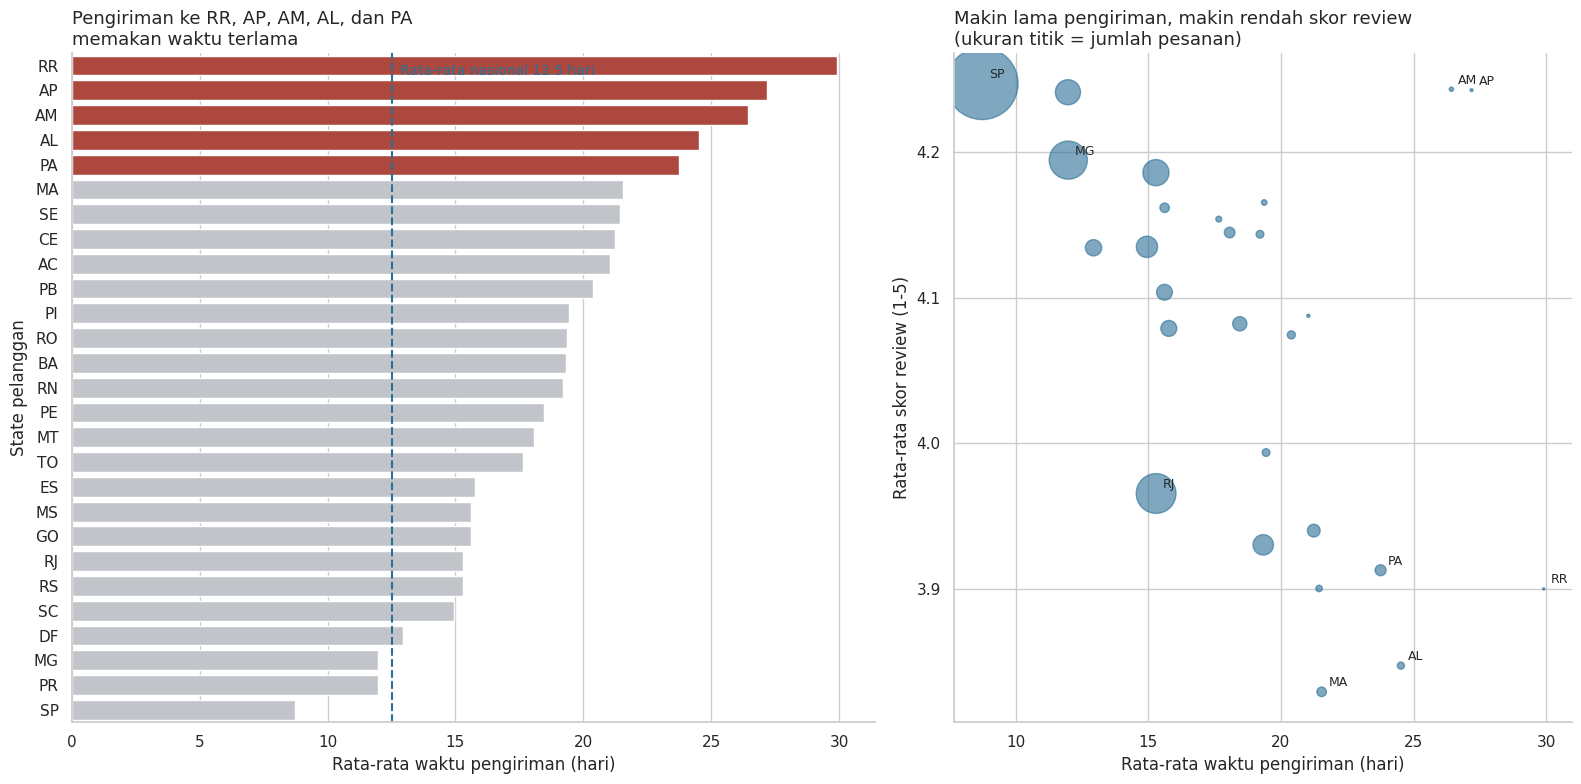

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={'width_ratios': [1.3, 1]})

ax = axes[0]
s = state_stats.sort_values('avg_delivery_days', ascending=False)
slowest5 = s.index[:5]
colors = [ALERT if st in slowest5 else GRAY for st in s.index]
sns.barplot(x=s.avg_delivery_days, y=s.index, palette=colors, hue=s.index, legend=False, ax=ax)
ax.axvline(order_level.delivery_days.mean(), color=ACCENT, linestyle='--')
ax.text(order_level.delivery_days.mean() + .3, 0.4, f'Rata-rata nasional {order_level.delivery_days.mean():.1f} hari', color=ACCENT, fontsize=10)
ax.set_title('Pengiriman ke RR, AP, AM, AL, dan PA\nmemakan waktu terlama', loc='left', fontsize=13)
ax.set_xlabel('Rata-rata waktu pengiriman (hari)'); ax.set_ylabel('State pelanggan')

ax = axes[1]
ax.scatter(state_stats.avg_delivery_days, state_stats.avg_review, s=state_stats.orders / 15, color=ACCENT, alpha=.6)
for st, r_ in state_stats.iterrows():
    if r_.avg_delivery_days > 22 or r_.orders > 10000 or r_.avg_review < 3.85:
        ax.annotate(st, (r_.avg_delivery_days, r_.avg_review), xytext=(5, 4), textcoords='offset points', fontsize=9)
ax.set_title('Makin lama pengiriman, makin rendah skor review\n(ukuran titik = jumlah pesanan)', loc='left', fontsize=13)
ax.set_xlabel('Rata-rata waktu pengiriman (hari)'); ax.set_ylabel('Rata-rata skor review (1-5)')
sns.despine(); plt.tight_layout(); plt.show()

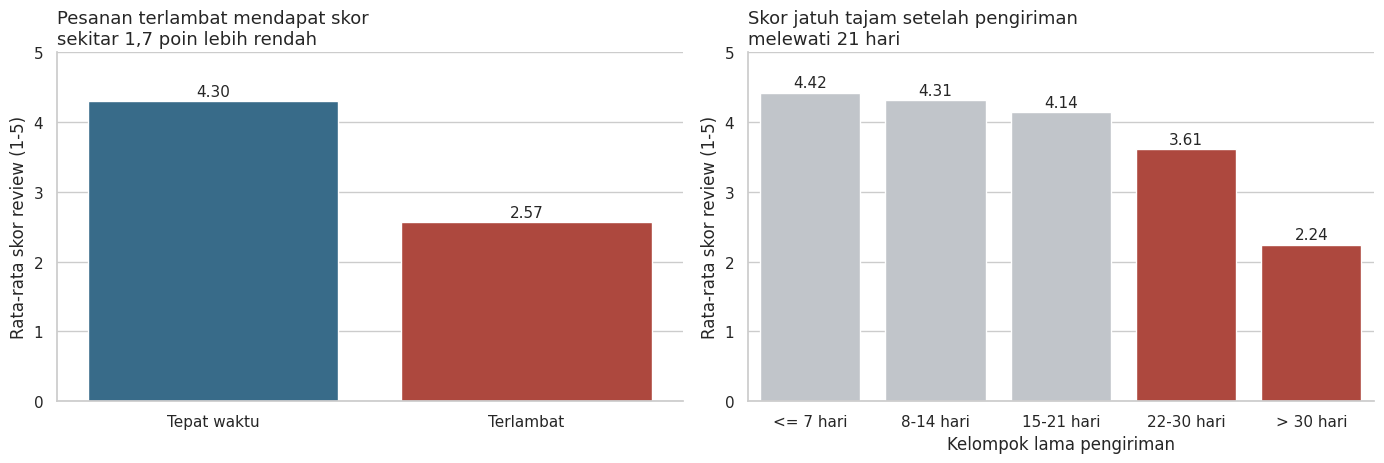

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
lr = order_level.groupby('is_late').review_score.mean().rename({False: 'Tepat waktu', True: 'Terlambat'})
sns.barplot(x=lr.index, y=lr.values, palette=[ACCENT, ALERT], hue=lr.index, legend=False, ax=ax)
ax.set_title('Pesanan terlambat mendapat skor\nsekitar 1,7 poin lebih rendah', loc='left', fontsize=13)
ax.set_xlabel(''); ax.set_ylabel('Rata-rata skor review (1-5)'); ax.set_ylim(0, 5)
for i, v in enumerate(lr.values):
    ax.text(i, v + .08, f'{v:.2f}', ha='center', fontsize=11)

ax = axes[1]
colors = [GRAY, GRAY, GRAY, ALERT, ALERT]
sns.barplot(x=bin_stats.index.astype(str), y=bin_stats['mean'].values, palette=colors, hue=bin_stats.index.astype(str), legend=False, ax=ax)
ax.set_title('Skor jatuh tajam setelah pengiriman\nmelewati 21 hari', loc='left', fontsize=13)
ax.set_xlabel('Kelompok lama pengiriman'); ax.set_ylabel('Rata-rata skor review (1-5)'); ax.set_ylim(0, 5)
for i, v in enumerate(bin_stats['mean'].values):
    ax.text(i, v + .08, f'{v:.2f}', ha='center', fontsize=11)
sns.despine(); plt.tight_layout(); plt.show()

**Insight :** Ada hubungan negatif yang jelas antara lama pengiriman dan kepuasan (korelasi antar state sekitar -0,46). Pesanan tepat waktu rata-rata bernilai 4,30 sedangkan pesanan terlambat hanya 2,57 (selisih sekitar 1,7 poin). Skor tetap tinggi (>= 4,1) hingga pengiriman 21 hari, lalu turun menjadi 3,61 pada 22-30 hari dan 2,24 pada > 30 hari. Catatan: AM dan AP lambat tetapi jarang terlambat (estimasi pengiriman mereka sudah realistis) dengan skor tetap tinggi, sehingga yang menurunkan kepuasan adalah *keterlambatan terhadap estimasi*, bukan lama pengiriman semata. Wilayah dengan pengiriman terlama dan tingkat keterlambatan tinggi (AL 24%, MA 20%, PI 16%, CE 15%, BA 14%, RJ 14%) berpotensi besar diperbaiki.

## Analisis Lanjutan (Opsional)

Bagian ini menerapkan tiga teknik analisis lanjutan tanpa machine learning: **RFM Analysis** (segmentasi pelanggan), **Geospatial Analysis** (peta sebaran revenue dan waktu pengiriman), dan **Binning** (pengelompokan lama pengiriman, dipakai pada Pertanyaan 2).

### RFM Analysis (Pertanyaan 3): Segmentasi Pelanggan

**Tujuan teknik:** RFM mengelompokkan pelanggan berdasarkan perilaku belanja:
- **Recency** = jumlah hari sejak pembelian terakhir (acuan: sehari setelah tanggal pembelian terakhir pada data),
- **Frequency** = jumlah pesanan unik,
- **Monetary** = total pengeluaran (harga barang, tanpa ongkir).

Pelanggan dihitung per **customer_unique_id**. Karena sekitar 97% pelanggan hanya membeli satu kali, pembagian kuintil Frequency tidak informatif, sehingga digunakan **manual grouping** berbasis aturan bisnis: Repeat Buyers (Frequency >= 2); pembeli satu kali dipisah berdasarkan Recency (<= 180 hari = recent) dan Monetary (kuartil teratas = high spender).

In [24]:
ref_date = main_df.order_purchase_timestamp.max() + pd.Timedelta(days=1)
rfm = (main_df.groupby('customer_unique_id')
       .agg(last_order=('order_purchase_timestamp', 'max'), Frequency=('order_id', 'nunique'), Monetary=('price', 'sum'))
       .reset_index())
rfm['Recency'] = (ref_date - rfm.last_order).dt.days
m_q75 = rfm.Monetary.quantile(.75)

def segment(row):
    if row.Frequency >= 2:
        return 'Repeat Buyers'
    if row.Recency <= 180:
        return 'Recent High Spenders' if row.Monetary >= m_q75 else 'Recent Customers'
    return 'At-Risk High Spenders' if row.Monetary >= m_q75 else 'Dormant Customers'

rfm['segment'] = rfm.apply(segment, axis=1)
print(f'Batas high spender (kuartil 3 Monetary): {m_q75:,.1f}')
print(f'Pelanggan yang membeli lebih dari sekali: {(rfm.Frequency > 1).mean():.1%}')
seg_stats = (rfm.groupby('segment')
             .agg(customers=('customer_unique_id', 'count'), revenue=('Monetary', 'sum'),
                  avg_recency=('Recency', 'mean'), avg_monetary=('Monetary', 'mean')))
seg_stats['pct_customers'] = seg_stats.customers / seg_stats.customers.sum() * 100
seg_stats['pct_revenue'] = seg_stats.revenue / seg_stats.revenue.sum() * 100
seg_stats = seg_stats.sort_values('pct_revenue', ascending=False).round(1)
seg_stats

Batas high spender (kuartil 3 Monetary): 154.0
Pelanggan yang membeli lebih dari sekali: 3.0%


,customers,revenue,avg_recency,avg_monetary,pct_customers,pct_revenue
segment,,,,,,
At-Risk High Spenders,12736,4448408.0,340.0,349.3,13.7,33.8
Recent High Spenders,8882,3177085.3,93.5,357.7,9.5,24.1
Dormant Customers,40689,2832411.0,336.5,69.6,43.7,21.5
Recent Customers,27987,1994365.7,91.8,71.3,30.1,15.1
Repeat Buyers,2786,724336.2,219.3,260.0,3.0,5.5


#### Visualisasi RFM (Pertanyaan 3)

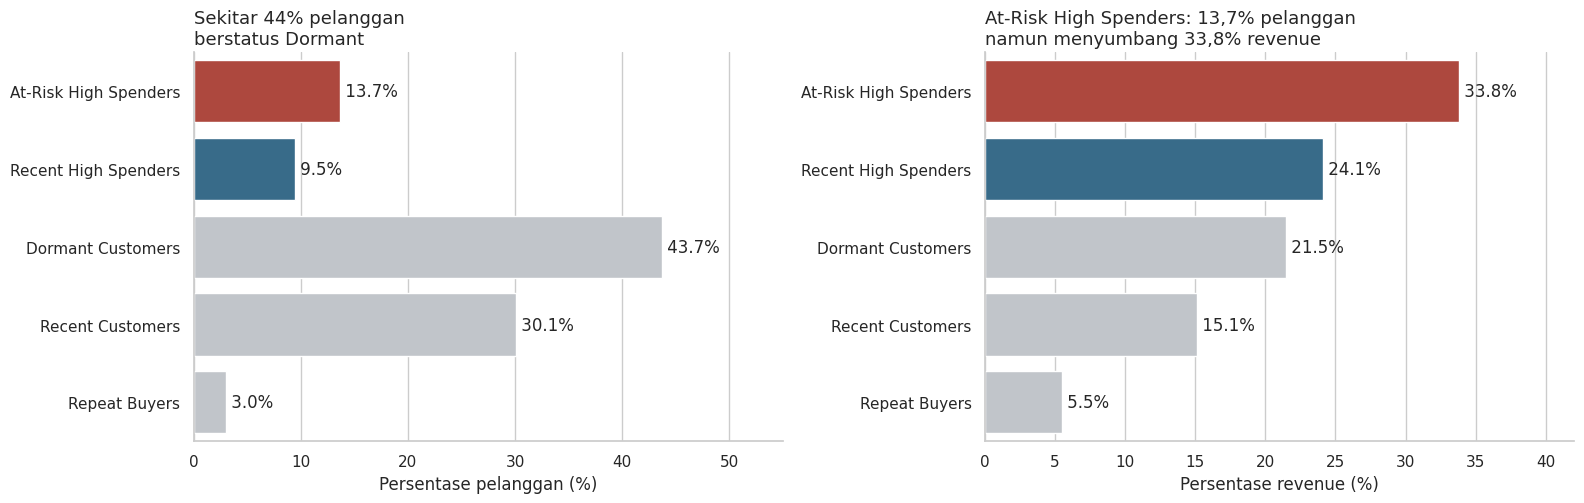

In [25]:
order_seg = ['At-Risk High Spenders', 'Recent High Spenders', 'Dormant Customers', 'Recent Customers', 'Repeat Buyers']
ss = seg_stats.loc[order_seg]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
colors = [ALERT, ACCENT, GRAY, GRAY, GRAY]

ax = axes[0]
sns.barplot(x=ss.pct_customers, y=ss.index, palette=colors, hue=ss.index, legend=False, ax=ax)
ax.set_title('Sekitar 44% pelanggan\nberstatus Dormant', loc='left', fontsize=13)
ax.set_xlabel('Persentase pelanggan (%)'); ax.set_ylabel('')
for i, v in enumerate(ss.pct_customers): ax.text(v, i, f' {v:.1f}%', va='center')
ax.set_xlim(0, 55)

ax = axes[1]
sns.barplot(x=ss.pct_revenue, y=ss.index, palette=colors, hue=ss.index, legend=False, ax=ax)
ax.set_title('At-Risk High Spenders: 13,7% pelanggan\nnamun menyumbang 33,8% revenue', loc='left', fontsize=13)
ax.set_xlabel('Persentase revenue (%)'); ax.set_ylabel('')
for i, v in enumerate(ss.pct_revenue): ax.text(v, i, f' {v:.1f}%', va='center')
ax.set_xlim(0, 42)
sns.despine(); plt.tight_layout(); plt.show()

**Insight Pertanyaan 3:** Basis pelanggan didominasi pembeli satu kali. Segmen **At-Risk High Spenders** (belanja besar, tetapi > 180 hari tidak kembali) hanya 13,7% pelanggan namun menyumbang 33,8% revenue, sedangkan **Repeat Buyers** hanya 3% pelanggan (5,5% revenue). Artinya retensi masih lemah dan terdapat peluang besar pada reaktivasi pelanggan bernilai tinggi.

### Geospatial Analysis

**Tujuan teknik:** memetakan sebaran revenue dan rata-rata waktu pengiriman per state pelanggan untuk melihat pola wilayah. Ukuran lingkaran menunjukkan revenue, warna menunjukkan rata-rata waktu pengiriman (biru = cepat, merah = lambat). Koordinat state dihitung dari rata-rata koordinat zip code pelanggan pada data geolocation yang sudah dibersihkan.

In [26]:
geo_state = (main_df.groupby('customer_state')
             .agg(revenue=('price', 'sum'), orders=('order_id', 'nunique'), avg_delivery=('delivery_days', 'mean'))
             .reset_index().merge(state_geo, on='customer_state'))

def color(d):
    return '#C0392B' if d >= 20 else ('#E67E22' if d >= 14 else '#2A6F97')

m = folium.Map(location=[-15.0, -52.0], zoom_start=4, tiles='OpenStreetMap')
for _, r_ in geo_state.iterrows():
    folium.CircleMarker(
        location=[r_.lat, r_.lng], radius=4 + (r_.revenue / geo_state.revenue.max()) * 28,
        color=color(r_.avg_delivery), fill=True, fill_opacity=.6,
        tooltip=f'{r_.customer_state}: revenue {r_.revenue:,.0f} | {r_.orders:,} pesanan | pengiriman {r_.avg_delivery:.1f} hari').add_to(m)
m

In [27]:
top_rev = geo_state.sort_values('revenue', ascending=False)
top_rev['pct'] = top_rev.revenue / top_rev.revenue.sum() * 100
print(top_rev[['customer_state', 'revenue', 'pct', 'avg_delivery']].head(6).round(1).to_string(index=False))
print('Kontribusi SP + RJ + MG:', round(top_rev.pct.head(3).sum(), 1), '%')

customer_state   revenue  pct  avg_delivery
            SP 5052686.2 38.3           8.7
            RJ 1751433.8 13.3          15.1
            MG 1547473.3 11.7          12.0
            RS  726037.9  5.5          15.2
            PR  664048.0  5.0          11.9
            SC  504323.6  3.8          15.0
Kontribusi SP + RJ + MG: 63.4 %


**Insight Geospatial:** Revenue sangat terpusat di wilayah tenggara Brasil: SP (38,3%), RJ (13,3%), dan MG (11,7%) menyumbang total 63,4% revenue, sedangkan wilayah utara dan timur laut berkontribusi kecil namun memiliki waktu pengiriman terlama (lingkaran merah). Pola ini konsisten dengan temuan pada Pertanyaan 2 bahwa jarak ke pusat logistik menjadi faktor utama lamanya pengiriman.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Top 10 kategori produk menyumbang 62,5% dari total revenue Jan 2017 - Agu 2018 (13,18 juta). Seluruh kategori tumbuh pada Jan-Agu 2018 dibanding Jan-Agu 2017. Urutan revenue (total periode) dan pertumbuhannya:
  1. `health_beauty`: 1.229 ribu (9,3% dari total), tumbuh **+210,5%**
  2. `watches_gifts`: 1.163 ribu (8,8%), tumbuh **+242,0%** (tertinggi)
  3. `bed_bath_table`: 1.023 ribu (7,8%), tumbuh **+109,6%**
  4. `sports_leisure`: 952 ribu (7,2%), tumbuh **+139,0%**
  5. `computers_accessories`: 888 ribu (6,7%), tumbuh **+131,4%**
  6. `furniture_decor`: 706 ribu (5,4%), tumbuh **+124,0%**
  7. `housewares`: 614 ribu (4,7%), tumbuh **+207,7%**
  8. `cool_stuff`: 609 ribu (4,6%), tumbuh **+10,4%** (terendah)
  9. `auto`: 578 ribu (4,4%), tumbuh **+174,1%**
  10. `garden_tools`: 469 ribu (3,6%), tumbuh **+54,0%**

  Insight: kategori dengan revenue terbesar (`health_beauty`) dan pertumbuhan tertinggi (`watches_gifts`) berbeda, sedangkan `cool_stuff` dan `garden_tools` tumbuh jauh di bawah kategori lain sehingga posisinya rawan tersalip.
- **Conclusion pertanyaan 2:** Rata-rata waktu pengiriman nasional 12,5 hari, rata-rata skor review 4,16, dan 8,1% pesanan terlambat dari estimasi.
  - *Pengiriman tercepat:* SP 8,7 hari (skor 4,25), PR 12,0 hari (4,24), MG 12,0 hari (4,19).
  - *Pengiriman terlama:* RR 29,9 hari (skor 3,90), AP 27,2 hari (4,24), AM 26,4 hari (4,24), AL 24,5 hari (3,85), PA 23,8 hari (3,91).
  - *Skor review terendah:* MA 3,83, AL 3,85, SE 3,90, RR 3,90, PA 3,91. *Keterlambatan tertinggi:* AL 24,0%, MA 19,6%, PI 16,0%, CE 15,4%, SE 15,4%.
  - *Selisih skor:* pesanan tepat waktu rata-rata 4,30, pesanan terlambat 2,57, selisih sekitar 1,73 poin. Skor tetap >= 4,14 hingga pengiriman 21 hari, turun menjadi 3,61 pada 22-30 hari dan 2,24 pada lebih dari 30 hari.

  Insight: yang menurunkan kepuasan adalah keterlambatan terhadap estimasi, bukan lama pengiriman semata (AM dan AP lambat tetapi jarang terlambat, skornya tetap 4,24). Wilayah yang perlu perbaikan prioritas adalah AL, MA, PA, SE, dan CE.
- **Conclusion pertanyaan 3:** Hanya 3,0% pelanggan yang membeli lebih dari sekali. Hasil segmentasi RFM (persentase pelanggan / persentase revenue):
  - At-Risk High Spenders: 13,7% / **33,8%** (rata-rata recency 340 hari, rata-rata belanja 349)
  - Recent High Spenders: 9,5% / 24,1%
  - Dormant Customers: 43,7% / 21,5%
  - Recent Customers: 30,1% / 15,1%
  - Repeat Buyers: 3,0% / 5,5%

  Insight: segmen penyumbang revenue terbesar adalah At-Risk High Spenders, yaitu pelanggan bernilai tinggi yang sudah lebih dari 180 hari tidak kembali, sehingga menjadi target reaktivasi paling bernilai.
- **Conclusion Geospatial:** Revenue terkonsentrasi di SP (38,3%), RJ (13,3%), dan MG (11,7%) dengan total 63,4% revenue, sementara wilayah utara dan timur laut memiliki waktu pengiriman terlama.

**Rekomendasi Action Item:**
1. **Prioritaskan stok dan promosi** pada **health_beauty**, **watches_gifts**, dan **bed_bath_table**, serta evaluasi strategi untuk **cool_stuff** yang pertumbuhannya paling lambat.
2. **Perbaiki logistik di wilayah lambat** (AL, MA, PA, CE, BA, dan wilayah utara): tambah pusat distribusi atau mitra kurir regional, dan tampilkan estimasi pengiriman yang lebih realistis. Targetkan pengiriman di bawah 21 hari karena skor review turun tajam setelahnya.
3. **Pantau pesanan berisiko terlambat** secara proaktif (notifikasi, kompensasi voucher) untuk menekan skor rendah akibat keterlambatan.
4. **Kampanye reaktivasi** (voucher personal, email pengingat) untuk segmen At-Risk High Spenders, dan program loyalitas untuk mendorong pembelian ulang dari Recent High Spenders dan Recent Customers.